## Packages

In [57]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import matplotlib.pyplot as plt 
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (StratifiedKFold, cross_val_predict, GridSearchCV)
# GridSearchCV stats
import time
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
import seaborn as sb

In [ ]:
# Structure
from Structure.Act_Cost import *
from Structure.DataProcess import Data_process
from Structure.NeuralNetwork import NeuralNetwork 
from Structure.Optimizer import Optimizer
from Structure.SGD import step_length, train_sgd
from Structure.PGD import train_plain
from Structure.NeuralNetRegressor import NeuralNetRegressor
from Structure.NeuralNetClassifier import NeuralNetClassifier

In [7]:
# Measures of quality
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

In [38]:
# LLM declaration (Claude Code, 2026-11-19): helper functions for the two-stage search.
# search_table collects cv_results_ in a DataFrame with short column names,
# CV accuracy, its standard error, training accuracy and mean fit time.
# n_params counts the trainable weights and biases of an FFNN with the given hidden layers.


def search_table(search):
    res = search.cv_results_
    df = pd.DataFrame([{key.split("__")[-1]: val for key, val in p.items()}
                       for p in res["params"]])
    df["score"] = res["mean_test_score"]
    df["score_se"] = res["std_test_score"] / np.sqrt(search.n_splits_ - 1)
    df["train_score"] = res["mean_train_score"]
    df["fit_time"] = res["mean_fit_time"]
    return df


def n_params(hidden, n_in=784, n_out=10):
    sizes = [n_in, *hidden, n_out]
    return sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))


# Data used for both stages. Replace with a larger stratified subset of the
# training data if desired; the test set is not used here.
X_search, y_search = X_sub, y_sub

## Mnist Fashion data

In [4]:
import numpy as np
data = np.load("fashion_mnist.npz")            
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
y_train = data["y_train"]
rng = np.random.default_rng(2026)
# 1000 data points in the subset
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 1000, replace=False) for c in range(10)])
X_sub, y_sub = x_train[sub], y_train[sub]
# Don`t touch this!
x_test_full = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_test_full = data["y_test"]

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

# Logistic Regression

In [5]:
acc_fold_L = []
for fold, (train_index, test_index) in enumerate(
    cv_strat.split(X_sub, y_sub), start=1):
    X_train, X_test = X_sub[train_index], X_sub[test_index]
    y_train, y_test = y_sub[train_index], y_sub[test_index]

    model = LogisticRegression(
    solver="lbfgs", max_iter=1000, random_state=2026
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    acc_fold_L.append(accuracy)
print("Accuracy per fold:", acc_fold_L)
print(f"Gjennomsnitt: {np.mean(acc_fold_L):.2%}")
print(f"Standard deviation: {np.std(acc_fold_L):.2%}")


Accuracy per fold: [0.834, 0.8265, 0.8265, 0.839, 0.8225]
Gjennomsnitt: 82.97%
Standard deviation: 0.60%


In [ ]:
# Gridsearch
# LLM Declaration: C_value grid found with help of Claude Code
C_values = np.logspace(-4,1,7)
results = {}
LR = LogisticRegression(C=1,
    solver="lbfgs", max_iter=1000, random_state=2026)
LR_model = make_pipeline(LR)
param_grid_lr = {"logisticregression__C": C_values}
Search_LR = GridSearchCV(LR_model, param_grid_lr, cv=cv_strat, scoring="accuracy",
                        return_train_score=True, n_jobs=-1)
t0 = time.perf_counter()
Search_LR.fit(X_train, y_train)
time = time.perf_counter() - t0

/Users/timholmen/FYS-STK4155/Project3/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Users/timholmen/FYS-STK4155/Project3/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://sciki

In [33]:
print(f"{len(Search_LR.cv_results_['params'])} configurations x "
      f"{Search_LR.n_splits_} folds in {time:.0f} s")


7 configurations x 5 folds in 253 s


## Measures of quality for logistic regression

          C     score  score_se  train_score   fit_time
0    0.0001  0.700250  0.002988     0.700187   4.810453
1    0.0010  0.762375  0.003465     0.768312   9.345881
2    0.0100  0.822125  0.005320     0.839719  13.980982
3    0.1000  0.841250  0.002245     0.893875  17.433439
4    1.0000  0.825250  0.004015     0.943844  28.884469
5   10.0000  0.801750  0.003970     0.985563  51.656534
6  100.0000  0.783875  0.003890     0.998937  50.101819
3


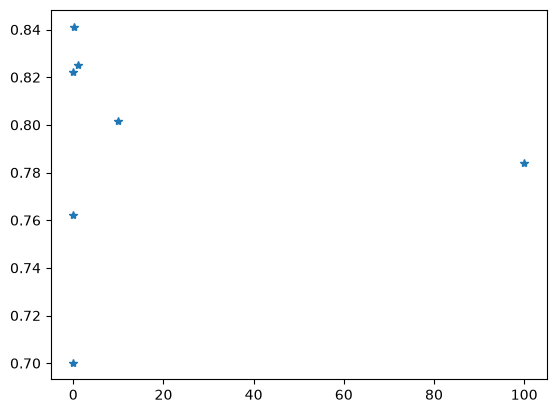

In [55]:
df_lr = search_table(Search_LR)
df_lr["C"] = C_values
print(df_lr)
best = df_lr["score"].idxmax()
print(best)
best_C = df_lr["C"][best]

limit = df_lr.loc[best,"score"] - df_lr.loc[best,"score_se"]
eligible = df_lr[df_lr["score"] >= limit]

C_values = df_lr["C"]
CV_score = df_lr["score"]
plt.plot(C_values,CV_score, "*")
plt.show()

## GridsearchCV

## Two-stage hyperparameter search
(LLM-assisted: the cells in this section were written with Claude Code, 2026-11-19.)

Instead of crossing every hyperparameter (672 configurations), the search is split in two.
Only the **Adam** optimizer is used, since it is the most robust choice with respect to the learning rate
(the comparison of optimizers is not the focus of this project).

- **Stage A – learning rate and epochs.** Fixed architecture `(64,)`, ReLU, L2 with λ = 1e-4.
  The number of epochs is searched because the network reaches ~100 % training accuracy
  after 10–20 epochs on 800 images, so epochs act as regularization (no early stopping).
- **Stage B – capacity and regularization.** γ and epochs chosen in stage A are kept fixed,
  and hidden layers × L2 strength λ × activation are searched. L1 is dropped (L2 / weight decay is the standard choice).

Both stages use `float32` and a fixed batch size of 50. The one-SE rule (SE = std/√(k−1)) picks
the cheapest model within one SE of the best: fewest epochs in stage A, fewest parameters in stage B.

Note: γ is tuned with ReLU in stage A, so sigmoid in stage B is compared at a step length chosen for ReLU.

In [ ]:
# LLM declaration (Claude Code, 2026-11-19): helper functions for the two-stage search.
# search_table collects cv_results_ in a DataFrame with short column names,
# CV accuracy, its standard error, training accuracy and mean fit time.
# n_params counts the trainable weights and biases of an FFNN with the given hidden layers.


def search_table(search):
    res = search.cv_results_
    df = pd.DataFrame([{key.split("__")[-1]: val for key, val in p.items()}
                       for p in res["params"]])
    df["val"] = res["mean_test_score"]
    df["val_se"] = res["std_test_score"] / np.sqrt(search.n_splits_ - 1)
    df["train"] = res["mean_train_score"]
    df["fit_time"] = res["mean_fit_time"]
    return df


def n_params(hidden, n_in=784, n_out=10):
    sizes = [n_in, *hidden, n_out]
    return sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))


# Data used for both stages. Replace with a larger stratified subset of the
# training data if desired; the test set is not used here.
X_search, y_search = X_sub, y_sub

### Stage A: learning rate and epochs (Adam)

In [32]:
# LLM declaration (Claude Code, 2026-11-19): stage A grid search, Adam only.
# 6 step lengths x 4 epoch values = 24 configurations. The ranges extend one step
# beyond earlier results (gamma = 1e-2 and 3e-2, 5 epochs) so the selection is not at the grid edge.
# [Changed 2026-11-19, LLM-assisted] gamma = 3e-2 added after gamma = 1e-2 was selected at the edge.
param_grid_A = {
    "neuralnetclassifier__method": ["adam"],
    "neuralnetclassifier__hidden": [(64,)],
    "neuralnetclassifier__activation": ["relu"],
    "neuralnetclassifier__penalty": ["l2"],
    "neuralnetclassifier__lmbd": [1e-4],
    "neuralnetclassifier__gamma": [3e-4, 1e-3, 3e-3, 1e-2],
    "neuralnetclassifier__epochs": [10, 20, 50],
}

net_A = make_pipeline(
    StandardScaler(),
    NeuralNetClassifier(batch_size=50, dtype="float32", seed=2026),
)
search_A = GridSearchCV(net_A, param_grid_A, cv=cv_strat, scoring="accuracy",
                        return_train_score=True, n_jobs=-1)

t0 = time.perf_counter()
search_A.fit(X_search, y_search)
time_A = time.perf_counter() - t0
print(f"Stage A: {len(search_A.cv_results_['params'])} configurations x "
      f"{search_A.n_splits_} folds in {time_A:.0f} s")

Stage A: 12 configurations x 5 folds in 179 s


Best CV accuracy: gamma=0.0003, epochs=20  CV=86.02% +/- 0.14%, train=94.89%, fit time=6.68 s
One-SE selection: gamma=0.0003, epochs=20  CV=86.02% +/- 0.14%, train=94.89%, fit time=6.68 s
One-SE limit: 85.88%


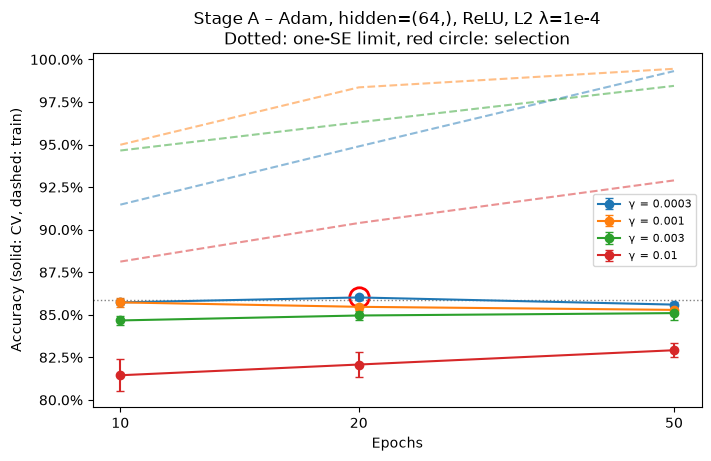

In [33]:
# LLM declaration (Claude Code, 2026-11-19): stage A selection and learning curves (Adam only).
# One-SE rule: among configurations within one SE of the best CV accuracy,
# choose the one with the fewest epochs (ties broken by higher CV accuracy).
df_A = search_table(search_A)
best_A = df_A["val"].idxmax()
limit_A = df_A.loc[best_A, "val"] - df_A.loc[best_A, "val_se"]
eligible_A = df_A[df_A["val"] >= limit_A]
sel_A = eligible_A.sort_values(["epochs", "val"], ascending=[True, False]).index[0]

for label, i in [("Best CV accuracy", best_A), ("One-SE selection", sel_A)]:
    r = df_A.loc[i]
    print(f"{label}: gamma={r['gamma']:g}, epochs={r['epochs']}  "
          f"CV={r['val']:.2%} +/- {r['val_se']:.2%}, train={r['train']:.2%}, "
          f"fit time={r['fit_time']:.2f} s")
print(f"One-SE limit: {limit_A:.2%}")

# CV accuracy (solid, with SE bars) and training accuracy (dashed) versus epochs,
# one line per learning rate.
epochs_A = sorted(df_A["epochs"].unique())
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
for gamma, d in df_A.groupby("gamma"):
    d = d.sort_values("epochs")
    eb = ax.errorbar(d["epochs"], d["val"], yerr=d["val_se"], marker="o",
                     capsize=3, label=f"γ = {gamma:g}")
    ax.plot(d["epochs"], d["train"], ls="--", alpha=0.5, color=eb[0].get_color())
r = df_A.loc[sel_A]
ax.plot(r["epochs"], r["val"], marker="o", ms=14, mfc="none", mec="red", mew=2)
ax.axhline(limit_A, color="gray", ls=":", lw=1)
ax.set_xscale("log")
ax.set_xticks(epochs_A, [str(e) for e in epochs_A])
ax.minorticks_off()
ax.set_xlabel("Epochs")
ax.set_ylabel("Accuracy (solid: CV, dashed: train)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend(fontsize=8)
ax.set_title("Stage A – Adam, hidden=(64,), ReLU, L2 λ=1e-4\n"
             "Dotted: one-SE limit, red circle: selection")
plt.show()

### Stage B: hidden layers, L2 strength and activation

In [34]:
# LLM declaration (Claude Code, 2026-11-19): stage B grid search.
# Adam, gamma and epochs are fixed to the stage A one-SE selection.
# 4 architectures x 4 lambdas x 2 activations = 32 configurations.
params_A = search_A.cv_results_["params"][sel_A]
fixed_B = {key: [params_A[key]] for key in (
    "neuralnetclassifier__method",
    "neuralnetclassifier__gamma",
    "neuralnetclassifier__epochs",
)}
param_grid_B = {
    **fixed_B,
    "neuralnetclassifier__hidden": [(32,), (64,), (128,)],
    "neuralnetclassifier__activation": ["relu", "sigmoid"],
    "neuralnetclassifier__penalty": ["l2"],
    "neuralnetclassifier__lmbd": [0, 1e-4, 1e-3, 1e-2],
}

search_B = GridSearchCV(net_A, param_grid_B, cv=cv_strat, scoring="accuracy",
                        return_train_score=True, n_jobs=-1)

t0 = time.perf_counter()
search_B.fit(X_search, y_search)
time_B = time.perf_counter() - t0
print("Fixed from stage A:", {k.split("__")[-1]: v[0] for k, v in fixed_B.items()})
print(f"Stage B: {len(search_B.cv_results_['params'])} configurations x "
      f"{search_B.n_splits_} folds in {time_B:.0f} s")

Fixed from stage A: {'method': 'adam', 'gamma': 0.0003, 'epochs': 20}
Stage B: 24 configurations x 5 folds in 244 s


Best CV accuracy: hidden=(128,), activation=relu, lambda=0.001  CV=86.11% +/- 0.18%, train=95.88%, parameters=101770, fit time=12.09 s
One-SE selection: hidden=(64,), activation=relu, lambda=0.001  CV=86.04% +/- 0.18%, train=94.21%, parameters=50890, fit time=6.46 s
One-SE limit: 85.93%


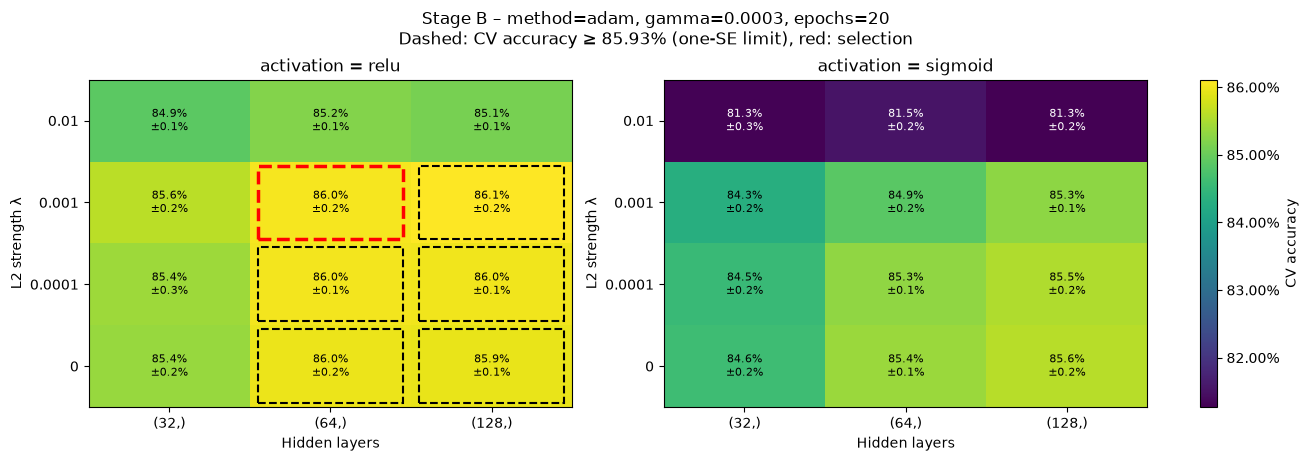

Selected FFNN: {'neuralnetclassifier__activation': 'relu', 'neuralnetclassifier__epochs': 20, 'neuralnetclassifier__gamma': 0.0003, 'neuralnetclassifier__hidden': (64,), 'neuralnetclassifier__lmbd': 0.001, 'neuralnetclassifier__method': 'adam', 'neuralnetclassifier__penalty': 'l2'}


In [35]:
# LLM declaration (Claude Code, 2026-11-19): stage B selection and heat maps.
# One-SE rule: among configurations within one SE of the best CV accuracy,
# choose the one with the fewest trainable parameters (ties: higher CV accuracy).
df_B = search_table(search_B)
df_B["hidden_str"] = df_B["hidden"].astype(str)
df_B["n_params"] = df_B["hidden"].apply(n_params)
best_B = df_B["val"].idxmax()
limit_B = df_B.loc[best_B, "val"] - df_B.loc[best_B, "val_se"]
eligible_B = df_B[df_B["val"] >= limit_B]
sel_B = eligible_B.sort_values(["n_params", "val"], ascending=[True, False]).index[0]

for label, i in [("Best CV accuracy", best_B), ("One-SE selection", sel_B)]:
    r = df_B.loc[i]
    print(f"{label}: hidden={r['hidden']}, activation={r['activation']}, "
          f"lambda={r['lmbd']:g}  CV={r['val']:.2%} +/- {r['val_se']:.2%}, "
          f"train={r['train']:.2%}, parameters={r['n_params']}, "
          f"fit time={r['fit_time']:.2f} s")
print(f"One-SE limit: {limit_B:.2%}")

hidden_B = [str(h) for h in param_grid_B["neuralnetclassifier__hidden"]]
lambdas_B = param_grid_B["neuralnetclassifier__lmbd"]
activations_B = param_grid_B["neuralnetclassifier__activation"]
vmin, vmax = df_B["val"].min(), df_B["val"].max()

fig, axes = plt.subplots(1, len(activations_B), figsize=(13, 4.5),
                         constrained_layout=True)
for ax, act in zip(axes, activations_B):
    d = df_B[df_B["activation"] == act]
    acc = d.pivot(index="lmbd", columns="hidden_str", values="val").reindex(
        index=lambdas_B, columns=hidden_B)
    se = d.pivot(index="lmbd", columns="hidden_str", values="val_se").reindex(
        index=lambdas_B, columns=hidden_B)
    idx = d.reset_index().pivot(index="lmbd", columns="hidden_str", values="index").reindex(
        index=lambdas_B, columns=hidden_B)
    im = ax.imshow(acc.values, origin="lower", aspect="auto", cmap="viridis",
                   vmin=vmin, vmax=vmax)
    for (row, col), a in np.ndenumerate(acc.values):
        ax.text(col, row, f"{a:.1%}\n±{se.values[row, col]:.1%}", ha="center",
                va="center", fontsize=8,
                color="white" if a < (vmin + vmax) / 2 else "black")
        if a >= limit_B:
            chosen = idx.values[row, col] == sel_B
            ax.add_patch(plt.Rectangle((col - 0.45, row - 0.45), 0.9, 0.9, fill=False,
                                       edgecolor="red" if chosen else "black",
                                       ls="--", lw=2.5 if chosen else 1.5))
    ax.set_xticks(range(len(hidden_B)), hidden_B)
    ax.set_yticks(range(len(lambdas_B)), [f"{l:g}" for l in lambdas_B])
    ax.set_xlabel("Hidden layers")
    ax.set_ylabel("L2 strength λ")
    ax.set_title(f"activation = {act}")
fig.colorbar(im, ax=axes.ravel().tolist(), label="CV accuracy",
             format=PercentFormatter(xmax=1))
fixed_txt = ", ".join(f"{k.split('__')[-1]}={v[0]}" for k, v in fixed_B.items())
fig.suptitle(f"Stage B – {fixed_txt}\n"
             f"Dashed: CV accuracy ≥ {limit_B:.2%} (one-SE limit), red: selection")
plt.show()

# Selected FFNN configuration (unfitted). Fit it on the full training subset
# and evaluate on the test set only once, at the end of the project.
ffnn_selected_params = search_B.cv_results_["params"][sel_B]
ffnn_selected = clone(net_A).set_params(**ffnn_selected_params)
print("Selected FFNN:", ffnn_selected_params)

In [37]:
def confusion_matrix(y_true, y_pred):
    """Eq. (5.67): the four counts TP, FN, FP, TN for labels in {0, 1}; the positive class is 1."""
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

best = search_class.best_estimator_ 
prediction_full = best.predict(x_test_full)
predictions_cv = cross_val_predict(best, X_sub, y_sub, cv=cv_strat)


NameError: name 'search_class' is not defined

Cross_val_predict: 85.500%
Best_NN_Predidt: 89.220%


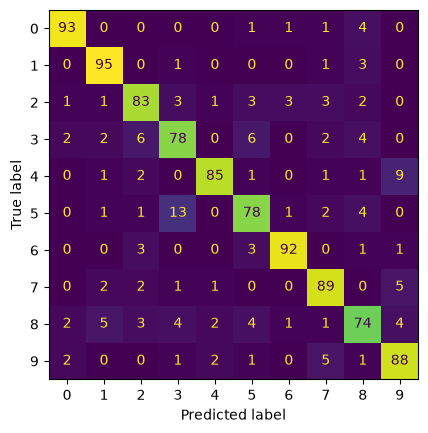

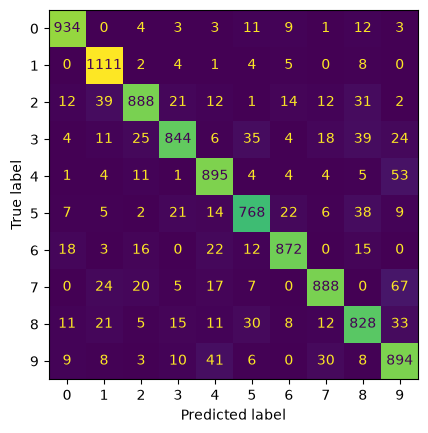

In [ ]:
cm = sk_confusion_matrix(y_sub, predictions_cv)
ConfusionMatrixDisplay(cm).plot(colorbar=False)
acc_score = accuracy_score(y_sub,predictions_cv)

cm_NN = sk_confusion_matrix(y_test_full, prediction_full)
ConfusionMatrixDisplay(cm_NN).plot(colorbar=False)
acc_NN = accuracy_score(y_test_full,prediction_full)
print(f"Cross_val_predict: {acc_score:.3%}")
print(f"Best_NN_Predidt: {acc_NN:.3%}")